# Layer Reuse

**Question:** when tasks share hidden representations, does the learner keep them and do as well as a baseline that is given them?

**Problems.** Teachers as in 02a: 21 random ±1 inputs → 10 LTUs → 10 LTUs → 10 linear outputs, with ±1 weights. First-layer LTUs fire when their weighted sum exceeds 2 (33% of inputs), and each second-layer LTU has its own threshold, chosen so it fires as close to 30% of the time as possible. Every task has its own second layer and readout. Targets have Gaussian noise of standard deviation 1. Tasks switch every 10k steps, in order, with no task ID. Each run is 2M steps: all tasks for 1M steps, only task 1 for 500k, then all tasks again for 500k.
- **Two Tasks, Shared First Layer:** both tasks use the same first layer.
- **Four Tasks, Two First Layers:** tasks 1 and 2 use one first layer, tasks 3 and 4 another.

**Learners.** Two LTU hidden layers with 1.5× the units the teachers use: 15 → 30 for two tasks and 30 → 60 for four. Every hidden unit is standardized as in 01a, and readout weights start at zero. Five seeds, shared by all methods.
- SGD with step sizes $2^{-10}$ to $2^{-6}$, and fan-in initialization of the hidden weights.
- Autostep: meta step 0.02, initial step size 1e-5, and hidden weights initialized uniformly in ±1e-5.
- Baseline: exactly the teacher LTUs, frozen (10 → 20 and 20 → 40), with each second-layer unit reading only the first-layer units of its own task. Only the readout learns, with Autostep, on the standardized second-layer units.
- Temporary: SGD without standardization (raw LTU bits, no centering, as in part one), with step sizes $2^{-9}$ to $2^{-5}$, to see whether it loses the other tasks' features during the one-task phase, as in 01a.

**Hypothesis.** Given enough time, SGD and Autostep reach the baseline: over the final 100k steps, Autostep and the best SGD step size are within 0.02 RMSE of the baseline.

The learning curves show the first and last 40k steps and 40k steps on each side of each phase change (dashed lines). The number above each block is the active task. Curves are means over seeds.

In [1]:
from functools import partial
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# Problems
N_INPUTS, WIDTH, N_OUTPUTS = 21, 10, 10
THRESHOLD = 2  # first-layer teacher LTUs fire on 33% of inputs
FIRING = .3  # target firing rate of second-layer teacher LTUs
PROBLEMS = {'Two Tasks, Shared First Layer': 1, 'Four Tasks, Two First Layers': 2}  # first layers
STEPS = 2_000_000
ONE_TASK = (1_000_000, 1_500_000)  # only task 1 is active between these steps
PERIOD = 10_000  # steps before switching to the next task
WINDOW = 1000
SIDE = 40_000  # steps shown at the start and end, and on each side of a phase change

# Methods
SGD_EXPONENTS = (-10, -9, -8, -7, -6)
RAW_EXPONENTS = (-9, -8, -7, -6, -5)  # temporary: SGD without standardization
INIT_RATE, META_RATE, EMA_RATE = 1e-5, .02, 1e-3
VAR_FLOOR = .01
N_SEEDS = 5
PROBE = jnp.asarray(np.random.default_rng(0).choice([-1., 1.], (10_000, N_INPUTS)), dtype=jnp.float32)

In [3]:
def init_task(key, first):
    """Second layer and readout of one task, on top of the given first layer."""
    second_key, out_key = jax.random.split(key)
    second = jax.random.rademacher(second_key, (WIDTH, WIDTH), dtype=jnp.float32)
    out = jax.random.rademacher(out_key, (N_OUTPUTS, WIDTH), dtype=jnp.float32)
    # Each second-layer threshold is the half-integer that makes the unit fire closest to 30% of the time.
    sums = second @ (first @ PROBE.T > THRESHOLD)
    candidates = jnp.arange(-WIDTH, WIDTH) + .5
    rates = (sums[:, None] > candidates[:, None]).mean(-1)
    return second, candidates[jnp.abs(rates - FIRING).argmin(1)], out


def init_teachers(key, groups):
    """Tasks 2k + 1 and 2k + 2 share first layer k + 1."""
    first_key, task_key = jax.random.split(key)
    first = jnp.repeat(jax.random.rademacher(first_key, (groups, WIDTH, N_INPUTS), dtype=jnp.float32), 2, axis=0)
    return first, *jax.vmap(init_task)(jax.random.split(task_key, 2 * groups), first)


def target(teacher, x):
    first, second, thresholds, out = teacher
    h = (first @ x > THRESHOLD).astype(jnp.float32)
    return out @ (second @ h > thresholds).astype(jnp.float32)


def true_layers(teachers, groups):
    """The teacher LTUs as hidden layers (unit, input + bias): each first layer once, then every task's second layer."""
    first, second, thresholds, _ = teachers
    layer1 = jnp.append(first[::2].reshape(-1, N_INPUTS), jnp.full((groups * WIDTH, 1), -THRESHOLD), axis=1)
    # A task's second-layer units read only the first-layer units of its own group.
    group = jax.nn.one_hot(jnp.arange(2 * groups) // 2, groups)
    layer2 = jnp.einsum('tij,tk->tikj', second, group).reshape(2 * groups * WIDTH, groups * WIDTH)
    return layer1, jnp.append(layer2, -thresholds.reshape(-1, 1), axis=1)

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True, tau=1e4, version='squared_inputs')


class Learner(NamedTuple):
    weights: tuple  # two hidden layers (unit, input + bias), then the readout (output, unit + bias)
    opt: object
    means: tuple  # running mean of each hidden unit
    slopes: tuple  # running mean of sigma'(z) x
    covs: tuple  # running covariance of the unit with sigma'(z) x


def init_learner(key, autostep, widths, hidden):
    if hidden is None:
        hidden, fan_in = [], N_INPUTS
        for subkey, width in zip(jax.random.split(key), widths):
            bound = jnp.where(autostep, INIT_RATE, np.sqrt(3 / fan_in))
            hidden.append(bound * jax.random.uniform(subkey, (width, fan_in + 1), minval=-1., maxval=1.).at[:, -1].set(0.))
            fan_in = width
    weights = (*hidden, jnp.zeros((N_OUTPUTS, widths[-1] + 1)))
    return Learner(weights, OPTIMIZER.init(weights),
                   tuple(jnp.full(len(w), .5) for w in hidden),
                   tuple(jnp.zeros_like(w).at[:, -1].set(.25) for w in hidden),
                   tuple(jnp.zeros_like(w) for w in hidden))


def forward(weights, x, learner, standardize, frozen):
    sources, means, slopes, covs = [], [], [], []
    for layer, (w, mean, slope, cov) in enumerate(zip(weights[:-1], learner.means, learner.slopes, learner.covs)):
        source = jnp.append(x, 1.)
        sources.append(source[None])
        z = w @ source
        bits = ltu(z)
        # Centering, with the backward pass accounting for how the mean changes with the input weights.
        mean = mean + EMA_RATE * (jax.lax.stop_gradient(bits) - mean)
        sigmoid = jax.nn.sigmoid(z)
        derivative = jax.lax.stop_gradient((sigmoid * (1 - sigmoid))[:, None] * source)
        slope = slope + EMA_RATE * (derivative - slope)
        correction = jnp.sum(slope * w, axis=1)
        centered = jax.lax.stop_gradient(bits - mean)
        h = bits - mean + (jax.lax.stop_gradient(correction) - correction)
        # Standardization: also divide by the running standard deviation, accounting for how it changes.
        cov = cov + EMA_RATE * (centered[:, None] * (derivative - slope) - cov)
        var = mean * (1 - mean)
        change = jnp.sum(cov * w, axis=1)
        floored = jnp.maximum(var, VAR_FLOOR)
        h = h - centered * jnp.where(var > VAR_FLOOR, (change - jax.lax.stop_gradient(change)) / floored, 0.)
        x = jnp.where(standardize, h / jnp.sqrt(floored), bits)
        if frozen and layer == 0:
            x = bits  # the baseline's frozen second layer reads the first-layer bits, like the teacher
        means.append(mean)
        slopes.append(slope)
        covs.append(cov)
    sources.append(jnp.append(x, 1.)[None])
    return weights[-1] @ sources[-1][0], (tuple(sources), tuple(means), tuple(slopes), tuple(covs))


def update(learner, x, y, autostep, rate, standardize, frozen):
    def loss(weights):
        prediction, aux = forward(weights, x, learner, standardize, frozen)
        return .5 * jnp.sum((prediction - y) ** 2), aux
    (loss_value, (sources, *stats)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    adaptive, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.weights)
    updates = jax.tree.map(lambda a, g: jnp.where(autostep, a, -rate * g), adaptive, grads)
    if frozen:
        updates = (*map(jnp.zeros_like, updates[:-1]), updates[-1])
    return Learner(jax.tree.map(jnp.add, learner.weights, updates), opt, *stats), 2 * loss_value / N_OUTPUTS

In [5]:
def train(seed, autostep, rate, standardize, groups, baseline):
    teacher_key, learner_key, rng = jax.random.split(jax.random.PRNGKey(seed), 3)
    teachers = init_teachers(teacher_key, groups)
    need = (groups * WIDTH, 2 * groups * WIDTH)  # hidden units the teachers use
    widths = need if baseline else tuple(3 * n // 2 for n in need)
    learner = init_learner(learner_key, autostep, widths, true_layers(teachers, groups) if baseline else None)

    def block(carry, block_id):
        one_task = (block_id * PERIOD >= ONE_TASK[0]) & (block_id * PERIOD < ONE_TASK[1])
        teacher = jax.tree.map(lambda w: w[block_id % jnp.where(one_task, 1, 2 * groups)], teachers)

        def sample(carry, _):
            learner, rng = carry
            rng, x_key, noise_key = jax.random.split(rng, 3)
            x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
            y = target(teacher, x) + jax.random.normal(noise_key, (N_OUTPUTS,))
            learner, mse = update(learner, x, y, autostep, rate, standardize, baseline)
            return (learner, rng), mse

        def record(carry, _):
            carry, mse = jax.lax.scan(sample, carry, length=WINDOW)
            return carry, mse.mean()
        return jax.lax.scan(record, carry, length=PERIOD // WINDOW)

    _, mse = jax.lax.scan(block, (learner, rng), jnp.arange(STEPS // PERIOD))
    return mse.reshape(-1)  # window-mean MSE


@partial(jax.jit, static_argnames=('groups', 'baseline'))
def run(autostep, rates, standardize, groups, baseline=False):
    seeds = jax.vmap(partial(train, groups=groups, baseline=baseline), in_axes=(0, None, None, None))
    return jax.vmap(seeds, in_axes=(None, 0, 0, 0))(jnp.arange(N_SEEDS), autostep, rates, standardize)

In [6]:
# SGD and Autostep run together, with the method as a flag. Temporary: SGD without standardization, last.
autostep = jnp.array([False] * len(SGD_EXPONENTS) + [True] + [False] * len(RAW_EXPONENTS))
rates = jnp.array([2. ** p for p in SGD_EXPONENTS] + [0.] + [2. ** p for p in RAW_EXPONENTS])
standardize = jnp.array([True] * (len(SGD_EXPONENTS) + 1) + [False] * len(RAW_EXPONENTS))
mse = {name: np.concatenate([run(autostep, rates, standardize, groups),
                             run(jnp.array([True]), jnp.zeros(1), jnp.array([True]), groups, baseline=True)])  # (method, seed, window)
       for name, groups in PROBLEMS.items()}

In [7]:
n = len(SGD_EXPONENTS)
LABELS = ([rf'SGD $2^{{{p}}}$' for p in SGD_EXPONENTS] + ['Autostep']
          + [rf'SGD $2^{{{p}}}$, no standardization' for p in RAW_EXPONENTS] + ['Baseline: teacher LTUs, frozen'])
COLORS = [*plt.cm.Reds(np.linspace(.4, .9, n)), 'tab:blue', *plt.cm.Oranges(np.linspace(.4, .9, len(RAW_EXPONENTS))), 'gray']


SECTIONS = [(0, SIDE), *((t - SIDE, t + SIDE) for t in ONE_TASK), (STEPS - SIDE, STEPS)]
x = np.arange(1, STEPS // WINDOW + 1) * WINDOW


def plot_curves(name, methods, title):
    tasks = 2 * PROBLEMS[name]
    fig, axes = plt.subplots(1, len(SECTIONS), figsize=(14, 4.5), sharey=True,
                             gridspec_kw={'wspace': .05, 'width_ratios': [right - left for left, right in SECTIONS]})
    headings = (f'{tasks} tasks', f'{tasks} → 1 task', f'1 → {tasks} tasks', f'{tasks} tasks')
    for ax, (left, right), heading in zip(axes, SECTIONS, headings):
        visible = (x > left) & (x <= right)
        for i in methods:
            ax.plot(x[visible], np.sqrt(mse[name][i][:, visible]).mean(0), color=COLORS[i], label=LABELS[i])
        ax.axhline(1, color='black', ls=':', label='Noise floor')
        for block in range(left // PERIOD, right // PERIOD):
            active = 1 if ONE_TASK[0] <= block * PERIOD < ONE_TASK[1] else tasks
            ax.text((block + .5) * PERIOD, 1.01, block % active + 1, ha='center', fontsize=8,
                    transform=ax.get_xaxis_transform())
        if right - left > SIDE:
            ax.axvline((left + right) / 2, color='black', ls='--', lw=1)  # phase change
        ticks = np.linspace(left, right, 3 if right - left > SIDE else 2).astype(int)
        ax.set_xticks(ticks, [f'{t // 1000}k' for t in ticks], fontsize=8)
        ax.get_xticklabels()[0].set_ha('left')
        ax.get_xticklabels()[-1].set_ha('right')
        ax.set_xlim(left, right)
        ax.grid(True, alpha=.3)
        ax.set_title(heading, pad=16, fontsize=10)
    # Two diagonal dashes mark each time skip.
    marks = dict(marker=[(-1, -1), (1, 1)], markersize=8, linestyle='none', color='black', clip_on=False)
    for ax in axes[:-1]:
        ax.spines['right'].set_visible(False)
        ax.plot([1, 1], [0, 1], transform=ax.transAxes, **marks)
    for ax in axes[1:]:
        ax.spines['left'].set_visible(False)
        ax.tick_params(axis='y', left=False)
        ax.plot([0, 0], [0, 1], transform=ax.transAxes, **marks)
    axes[0].set_ylabel('RMSE')
    axes[-1].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.1, 1))
    fig.suptitle(f'{title} | {name}')
    fig.supxlabel('Steps')
    fig.subplots_adjust(top=.8, bottom=.14, right=.8)
    plt.show()

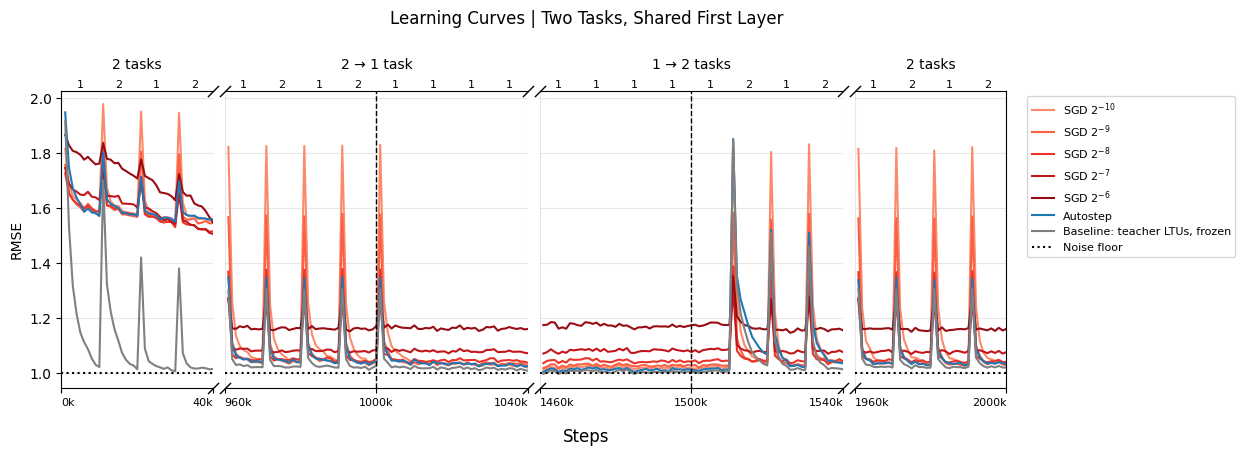

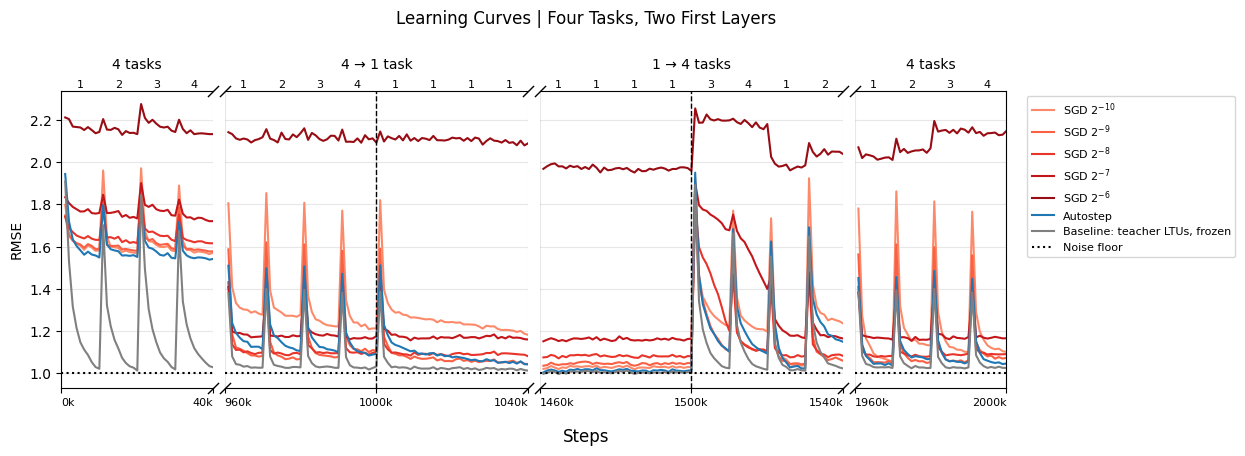

In [8]:
for name in PROBLEMS:
    plot_curves(name, [*range(n + 1), -1], 'Learning Curves')

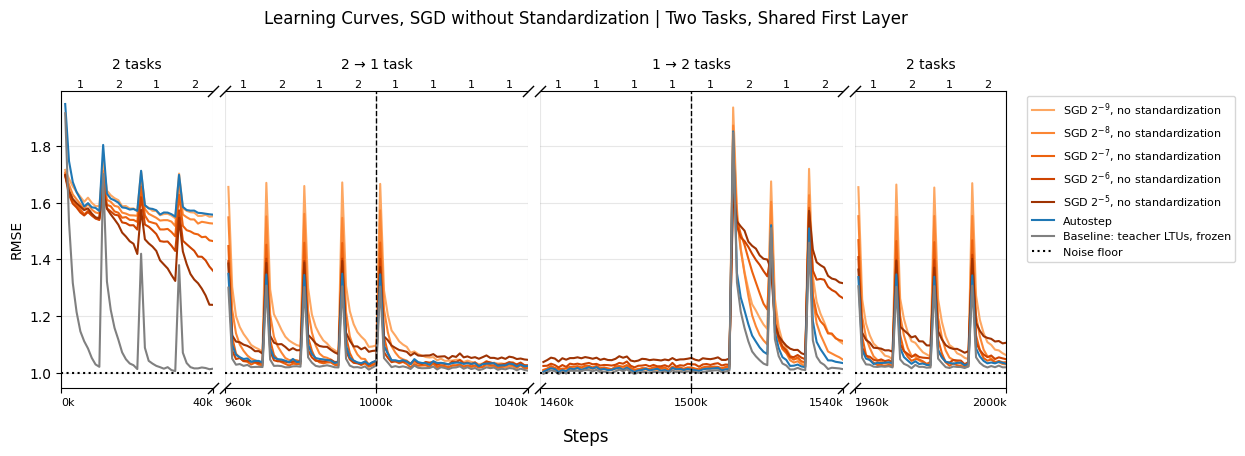

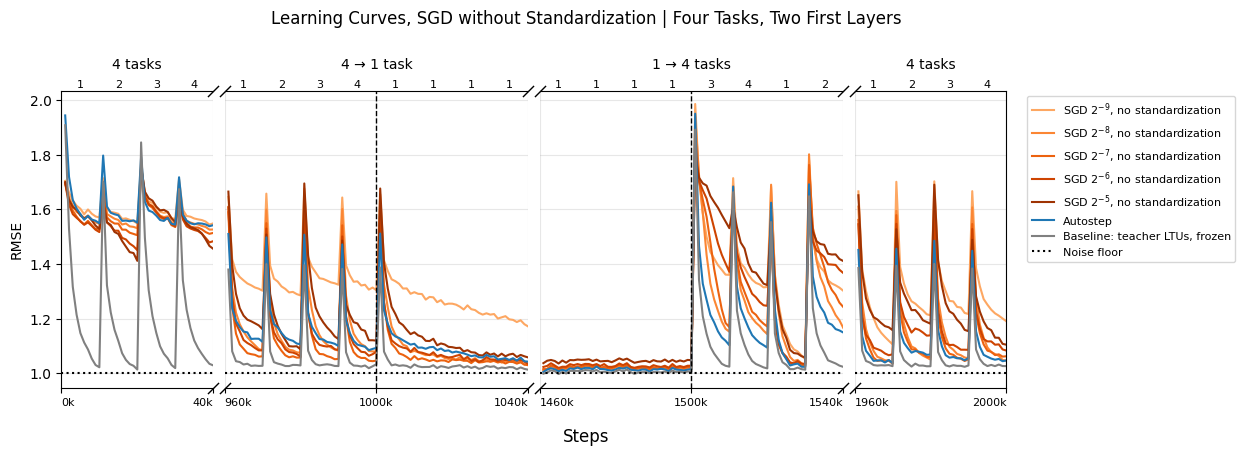

In [9]:
# Temporary: SGD without standardization, with Autostep and the baseline for reference.
for name in PROBLEMS:
    plot_curves(name, [*range(n + 1, 2 * n + 1), n, -1], 'Learning Curves, SGD without Standardization')